# BEKANTOR Demand Intelligence — cierre académico final

## tl;dr

- **LightGBM optimizado** fue el mejor candidato observado (`RMSLE = 0,389282`), pero la mejora relativa de `0,324 %` frente al original es pequeña y sólo se verificó en dos folds externos de desarrollo.
- V2 separa cuatro folds de tuning y dos de evaluación externa, todos anteriores a agosto. Esto es más sólido que comparar contra agosto ya explorado, pero no constituye un test final perfectamente ciego.
- La precisión se deteriora cuando el calendario promocional futuro está menos confirmado; los escenarios son supuestos informativos, no evidencia causal.
- En el escenario de estrés, el stock inicial supuesto es insuficiente: aparece un faltante el día 2 y se simulan `3.786,294` unidades potencialmente no atendidas antes de la recepción del día 4.
- BEKANTOR es un **prototipo experimental de apoyo a decisiones**, no un ERP ni una promesa de ahorro.

## Contexto y métodos

Este notebook recupera exclusivamente artefactos ya calculados en Forecasting V2 y el escenario de cierre reproducible. No ejecuta Optuna, LightGBM, CatBoost ni TSB.

### Fuentes y supuestos

- Fuente V2: `outputs/forecasting_v2_full/` (14 artefactos originales protegidos por SHA-256).
- Fuente de cierre: `outputs/forecasting_final/`.
- Horizonte: 15 días; lead time: 3 días; recepción al inicio del día 4.
- La demanda observada común sólo evalúa la simulación. No fija stock inicial, stock de seguridad ni reposición.
- Inventario, nivel de servicio y costos son supuestos. Los faltantes y costos son simulados.

In [1]:
from pathlib import Path
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "outputs" / "forecasting_v2_full").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del repositorio")


ROOT = find_repo_root(Path.cwd().resolve())
V2 = ROOT / "outputs" / "forecasting_v2_full"
FINAL = ROOT / "outputs" / "forecasting_final"
FINAL.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
MODEL_COLORS = {
    "LightGBM optimized": "#2563eb",
    "LightGBM original": "#d97706",
    "CatBoost": "#7c3aed",
    "Seasonal baseline": "#64748b",
    "TSB": "#0f766e",
}
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

manifest = json.loads((V2 / "run_manifest.json").read_text(encoding="utf-8"))
source_hashes = json.loads((FINAL / "source_v2_sha256.json").read_text(encoding="utf-8"))
assert manifest["protocol"] == "full"
assert manifest["august_evaluated"] is False
assert len(source_hashes) == 14
print("Fuente V2 verificada:", len(source_hashes), "artefactos")
print("Duración de la corrida reutilizada (h):", round(manifest["elapsed_seconds"] / 3600, 2))

Fuente V2 verificada: 14 artefactos
Duración de la corrida reutilizada (h): 9.32


## 1. Validación temporal: V1 y V2

V1 informó resultados sobre **01/08/2017–15/08/2017**, período ya visto durante el EDA. V2 evita usar agosto: los folds 1–4 sirven para tuning y los folds 5–6 para evaluación externa de desarrollo.

Las métricas de agosto y julio no deben compararse como si pertenecieran al mismo experimento: cambian la ventana, el contexto temporal y el protocolo. Los folds 5–6 son externos a Optuna, pero no un test final perfectamente ciego.

En la cronología, el extremo derecho de cada barra es exclusivo: el fold 6 incluye observaciones hasta el **31/07/2017** y la marca **01/08** señala solamente el límite exclusivo.

,fold,train_end,validation_start,validation_end,role
0,1,2017-05-02,2017-05-03,2017-05-17,tuning
1,2,2017-05-17,2017-05-18,2017-06-01,tuning
2,3,2017-06-01,2017-06-02,2017-06-16,tuning
3,4,2017-06-16,2017-06-17,2017-07-01,tuning
4,5,2017-07-01,2017-07-02,2017-07-16,development_evaluation
5,6,2017-07-16,2017-07-17,2017-07-31,development_evaluation


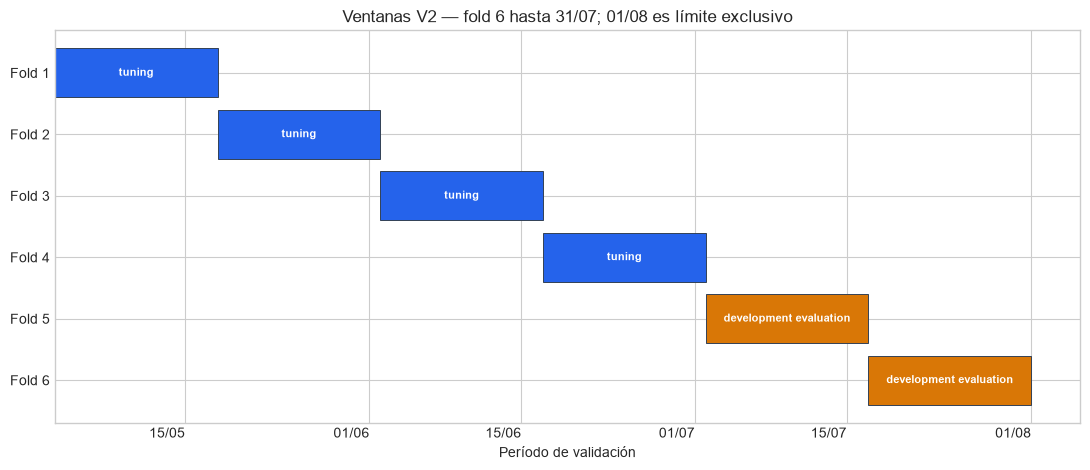

In [2]:
folds = pd.read_csv(
    V2 / "folds.csv",
    parse_dates=["train_end", "validation_start", "validation_end"],
)
assert folds["validation_end"].max() < pd.Timestamp("2017-08-01")
display(folds)

fig, ax = plt.subplots(figsize=(11, 4.8))
role_colors = {"tuning": "#2563eb", "development_evaluation": "#d97706"}
for row in folds.itertuples(index=False):
    start = mdates.date2num(row.validation_start)
    end = mdates.date2num(row.validation_end + pd.Timedelta(days=1))
    ax.barh(
        f"Fold {row.fold}",
        end - start,
        left=start,
        color=role_colors[row.role],
        edgecolor="#334155",
        linewidth=0.7,
    )
    ax.text(start + (end - start) / 2, f"Fold {row.fold}", row.role.replace("_", " "),
            ha="center", va="center", color="white", fontsize=8, fontweight="bold")
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set(title="Ventanas V2 — fold 6 hasta 31/07; 01/08 es límite exclusivo",
       xlabel="Período de validación", ylabel="")
fig.autofmt_xdate(rotation=0)
plt.tight_layout()
plt.savefig(FINAL / "validation_timeline.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Interpretación de la optimización

RMSLE mide la raíz del error cuadrático medio en escala `log1p`. La diferencia no se interpreta directamente como unidades, ventas, faltantes ni ahorro. Optuna fue útil para sistematizar una búsqueda limitada a cuatro folds y registrar 20 trials, aunque la ganancia resultante sea incremental.

La etapa Optuna consumió aproximadamente **5 h 26 min 34 s**; la corrida completa, **9 h 19 min 28 s**. Con sólo dos orígenes temporales externos no hay base para afirmar superioridad general ni para calcular significancia estadística o intervalos de confianza metodológicamente defendibles.

,métrica,valor
0,RMSLE original,0.3905
1,RMSLE optimizado,0.3893
2,mejora absoluta RMSLE,0.0013
3,mejora relativa RMSLE (%),0.3243
4,mejora WAPE (pp),0.1489
5,trials completos,17.0000
6,trials podados,3.0000
7,horas Optuna,5.4428


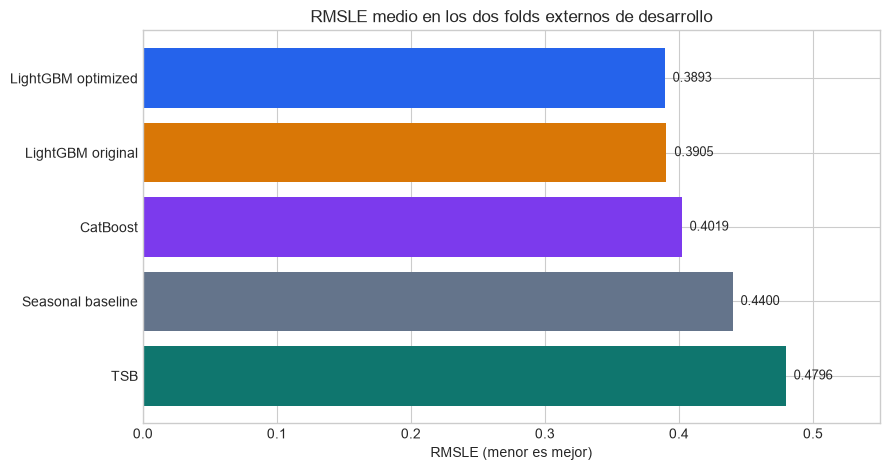

In [3]:
comparison = pd.read_csv(V2 / "model_comparison.csv")
trials = pd.read_csv(V2 / "optuna_trials.csv")
optimized = comparison.loc[comparison["model"].eq("LightGBM optimized")].iloc[0]
original = comparison.loc[comparison["model"].eq("LightGBM original")].iloc[0]
absolute_improvement = original.RMSLE_mean - optimized.RMSLE_mean
relative_improvement = absolute_improvement / original.RMSLE_mean * 100
wape_improvement_pp = original.WAPE_pct_mean - optimized.WAPE_pct_mean
optimization_readout = pd.DataFrame({
    "métrica": ["RMSLE original", "RMSLE optimizado", "mejora absoluta RMSLE",
                "mejora relativa RMSLE (%)", "mejora WAPE (pp)",
                "trials completos", "trials podados", "horas Optuna"],
    "valor": [original.RMSLE_mean, optimized.RMSLE_mean, absolute_improvement,
              relative_improvement, wape_improvement_pp,
              trials["state"].eq("COMPLETE").sum(), trials["state"].eq("PRUNED").sum(),
              manifest["stage_seconds"]["optuna_lightgbm"] / 3600],
})
display(optimization_readout.round(6))
assert np.isclose(relative_improvement, 0.3242862298)

ordered = comparison.sort_values("RMSLE_mean", ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(ordered["model"], ordered["RMSLE_mean"],
        color=[MODEL_COLORS[name] for name in ordered["model"]])
ax.invert_yaxis()
ax.set(title="RMSLE medio en los dos folds externos de desarrollo",
       xlabel="RMSLE (menor es mejor)", ylabel="", xlim=(0, 0.55))
for index, value in enumerate(ordered["RMSLE_mean"]):
    ax.text(value + 0.006, index, f"{value:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FINAL / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

**Conclusión:** LightGBM optimizado fue el mejor candidato observado. La evidencia de superioridad frente al original es limitada: la mejora absoluta es `0,001267` RMSLE, `0,324 %` relativa, y proviene de sólo dos ventanas externas.

## 3. Promociones disponibles al pronosticar

Un calendario promocional aprobado es el plan autorizado y comunicado antes del corte de forecast. Puede abarcar todo el horizonte, sólo algunos días o ninguno. Cuando no hay confirmación, el escenario imputa promociones con tasas históricas calculadas hasta el corte, sin usar información futura.

El dataset no contiene fechas de aprobación. Los escenarios son supuestos de disponibilidad informativa, no verificaciones históricas ni estimaciones causales.

,scenario,confirmed_days,RMSLE,RMSLE_delta,RMSLE_relative_pct,WAPE_pct,forecast_total
0,full,15,0.4008,0.0000,0.0000,11.7521,"12,050,318.0327"
1,partial,7,0.4280,0.0272,6.7834,11.9325,"11,939,339.4438"
2,none,0,0.4618,0.0610,15.2204,12.2260,"11,792,071.0221"


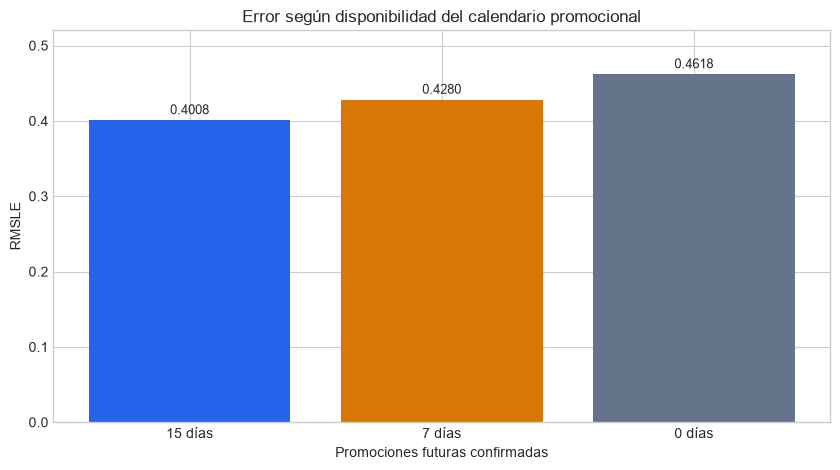

In [4]:
promotions = pd.read_csv(V2 / "promotion_scenarios.csv")
base_rmsle = promotions.loc[promotions["scenario"].eq("full"), "RMSLE"].iloc[0]
promotion_view = promotions.assign(
    RMSLE_delta=lambda frame: frame["RMSLE"] - base_rmsle,
    RMSLE_relative_pct=lambda frame: (frame["RMSLE"] / base_rmsle - 1) * 100,
)[["scenario", "confirmed_days", "RMSLE", "RMSLE_delta", "RMSLE_relative_pct",
   "WAPE_pct", "forecast_total"]]
display(promotion_view.round(4))

labels = {"full": "15 días", "partial": "7 días", "none": "0 días"}
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.bar([labels[value] for value in promotions["scenario"]], promotions["RMSLE"],
       color=["#2563eb", "#d97706", "#64748b"])
ax.set(title="Error según disponibilidad del calendario promocional",
       xlabel="Promociones futuras confirmadas", ylabel="RMSLE", ylim=(0, 0.52))
for index, value in enumerate(promotions["RMSLE"]):
    ax.text(index, value + 0.008, f"{value:.4f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FINAL / "promotion_availability.png", dpi=160, bbox_inches="tight")
plt.show()

La menor disponibilidad eleva RMSLE de `0,400791` a `0,427978` y `0,461793`. Para una empresa, el hallazgo respalda versionar el calendario, registrar fecha de aprobación y definir un SLA de comunicación entre Comercial, Abastecimiento y Datos. No demuestra que la promoción cause ventas.

## 4. Inventario: caso aprobado y escenario de estrés

La tienda 18 y la familia `PRODUCE` fueron **seleccionadas retrospectivamente en V2 según las ventas reales observadas durante la validación**. Se conservan exclusivamente como caso demostrativo; no constituyen una selección operativa prospectiva ni prueban que la serie sea representativa del negocio.

Una vez seleccionado el caso, el stock inicial y las reposiciones se determinan con pronósticos y supuestos disponibles antes del horizonte. Las ventas reales futuras se utilizan solamente para evaluar el resultado simulado y no intervienen en esas decisiones.

Ambos casos conservan horizonte de 15 días, lead time de 3 días, nivel de servicio de 95 %, stock de seguridad y costos unitarios comunes.

- **Caso V2 aprobado:** stock inicial igual a 25 % del pronóstico del baseline; no produce faltantes.
- **Estrés:** stock inicial igual a 10 % del mismo pronóstico (`2.951,916`); la regla es conocida antes del horizonte y no usa ventas futuras.

In [5]:
original_inventory = pd.read_csv(V2 / "inventory_example_summary.csv")
original_trajectory = pd.read_csv(V2 / "inventory_example_trajectory.csv")
stress = pd.read_csv(FINAL / "inventory_stress_summary.csv")
stress_trajectory = pd.read_csv(FINAL / "inventory_stress_trajectory.csv")
assumptions = json.loads((FINAL / "inventory_stress_assumptions.json").read_text(encoding="utf-8"))
assert assumptions["case_selection_retrospective"] is True
assert assumptions["case_selection_basis"] == "observed_validation_sales"
assert assumptions["future_actual_used_for_decision"] is False

original_view = original_inventory[[
    "model", "initial_stock_assumption", "forecast_demand",
    "recommended_replenishment", "potential_shortage", "ending_inventory",
    "simulated_total_cost",
]]
stress_view = stress[[
    "model", "initial_stock_assumption", "forecast_demand",
    "recommended_replenishment", "first_shortage_day", "potential_shortage",
    "ending_inventory", "simulated_total_cost",
]]
print("Caso original aprobado")
display(original_view.round(3))
print("Escenario de estrés")
display(stress_view.round(3))

Caso original aprobado


,model,initial_stock_assumption,forecast_demand,recommended_replenishment,potential_shortage,ending_inventory,simulated_total_cost
0,Seasonal baseline,"7,379.7900","29,519.1590","22,585.1730",0.0000,"2,170.5200","25,527.2000"
1,LightGBM original,"7,379.7900","30,390.5790","23,456.5930",0.0000,"3,041.9400","26,607.7610"
2,LightGBM optimized,"7,379.7900","29,424.2870","22,490.3010",0.0000,"2,075.6480","25,409.5590"
3,CatBoost,"7,379.7900","29,727.5300","22,793.5450",0.0000,"2,378.8920","25,785.5810"
4,TSB,"7,379.7900","29,919.1210","22,985.1360",0.0000,"2,570.4830","26,023.1540"


Escenario de estrés


,model,initial_stock_assumption,forecast_demand,recommended_replenishment,first_shortage_day,potential_shortage,ending_inventory,simulated_total_cost
0,Seasonal baseline,"2,951.9160","29,519.1590","23,348.7620",2,"3,786.2940","2,292.5290","33,754.9350"
1,LightGBM original,"2,951.9160","30,390.5790","24,022.5920",2,"3,786.2940","2,966.3590","34,590.4840"
2,LightGBM optimized,"2,951.9160","29,424.2870","23,035.0180",2,"3,786.2940","1,978.7850","33,365.8920"
3,CatBoost,"2,951.9160","29,727.5300","23,552.7770",2,"3,786.2940","2,496.5440","34,007.9140"
4,TSB,"2,951.9160","29,919.1210","24,381.1010",2,"3,786.2940","3,324.8680","35,035.0360"


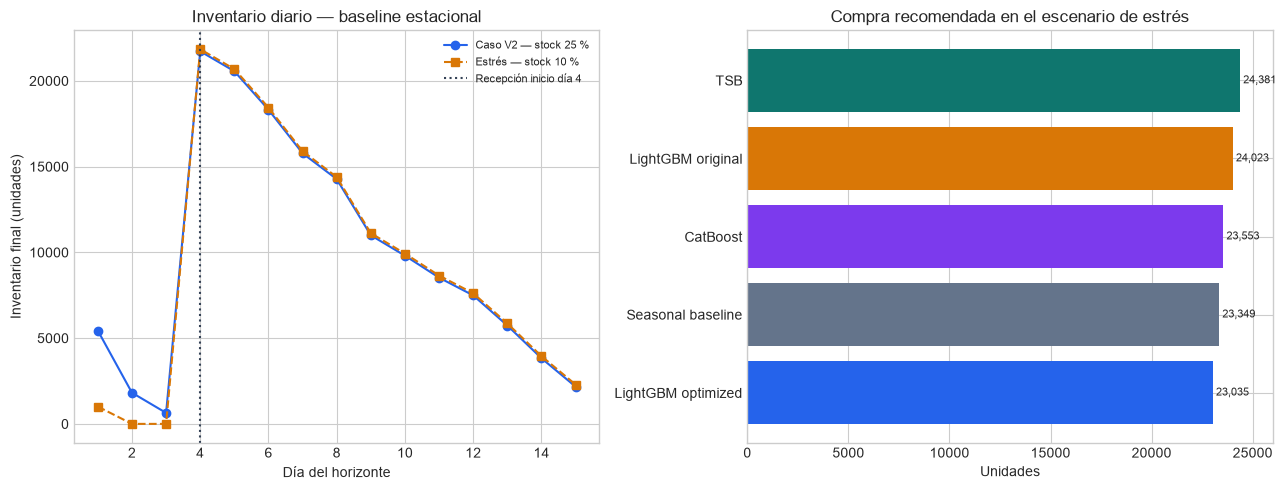

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
reference = "Seasonal baseline"
original_reference = original_trajectory.loc[
    original_trajectory["model"].eq(reference)
]
stress_reference = stress_trajectory.loc[
    stress_trajectory["model"].eq(reference)
]
axes[0].plot(original_reference["horizon_day"], original_reference["ending_inventory"],
             marker="o", color="#2563eb", label="Caso V2 — stock 25 %")
axes[0].plot(stress_reference["horizon_day"], stress_reference["ending_inventory"],
             marker="s", linestyle="--", color="#d97706", label="Estrés — stock 10 %")
axes[0].axvline(4, color="#334155", linestyle=":", label="Recepción inicio día 4")
axes[0].set(title="Inventario diario — baseline estacional",
            xlabel="Día del horizonte", ylabel="Inventario final (unidades)")
axes[0].legend(frameon=False, fontsize=8)

purchase_order = stress.sort_values("recommended_replenishment")
axes[1].barh(purchase_order["model"], purchase_order["recommended_replenishment"],
             color=[MODEL_COLORS[name] for name in purchase_order["model"]])
axes[1].set(title="Compra recomendada en el escenario de estrés",
            xlabel="Unidades", ylabel="", xlim=(0, 26000))
for index, value in enumerate(purchase_order["recommended_replenishment"]):
    axes[1].text(value + 150, index, f"{value:,.0f}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FINAL / "inventory_stress_trajectory.png", dpi=160, bbox_inches="tight")
plt.show()

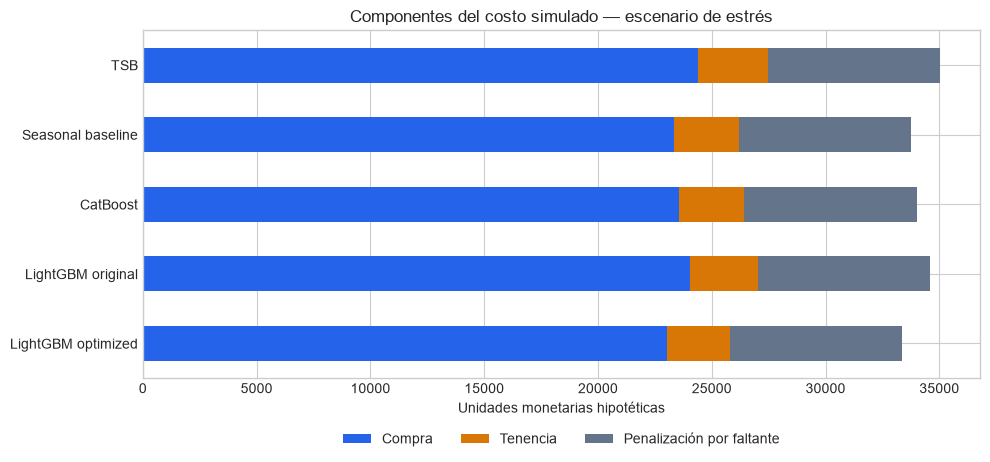

Unidades potencialmente no atendidas: 3786.294
Política de ventas perdidas: Los faltantes son ventas potencialmente no atendidas y no se acumulan como pedidos pendientes ni se recuperan tras la recepción.


In [7]:
cost_components = stress.set_index("model")[["purchase_cost", "holding_cost", "shortage_cost"]]
cost_components = cost_components.loc[list(MODEL_COLORS)]
ax = cost_components.plot(
    kind="barh", stacked=True, figsize=(10, 5.2),
    color=["#2563eb", "#d97706", "#64748b"],
)
ax.set(title="Componentes del costo simulado — escenario de estrés",
       xlabel="Unidades monetarias hipotéticas", ylabel="")
ax.legend(
    ["Compra", "Tenencia", "Penalización por faltante"],
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.savefig(FINAL / "inventory_stress_costs.png", dpi=160, bbox_inches="tight")
plt.show()

assert stress["first_shortage_day"].eq(2).all()
assert stress["potential_shortage"].nunique() == 1
assert stress_trajectory.loc[stress_trajectory["horizon_day"].ne(4), "receipt"].eq(0).all()
print("Unidades potencialmente no atendidas:", round(stress["potential_shortage"].iloc[0], 3))
print("Política de ventas perdidas:", assumptions["lost_sales_policy"])

El faltante empieza el **día 2** y suma `3.786,294` unidades potenciales en los días 2–3. La recepción llega al inicio del día 4. Las ventas no atendidas no se acumulan como pedidos pendientes, por lo que la reposición no puede recuperarlas. Cada modelo recomienda otra cantidad porque su demanda pronosticada posterior a la recepción es diferente.

Los costos son hipotéticos. No deben denominarse ahorro, pérdida o impacto económico real.

## 5. TSB y demanda irregular

TSB estima por separado probabilidad de ocurrencia y tamaño de demanda. Puede ser útil con numerosos ceros, pero no necesariamente supera a un modelo global con calendario, promociones, tienda, familia, lags y estadísticas móviles.

,segment,model,RMSLE,WAPE_pct
0,GROCERY II,CatBoost,0.6011,35.9497
1,GROCERY II,LightGBM optimized,0.5941,36.0750
2,GROCERY II,LightGBM original,0.5941,36.2677
3,GROCERY II,Seasonal baseline,0.6359,37.0512
4,GROCERY II,TSB,0.6164,36.6934
5,Intermitente,CatBoost,0.4046,14.7642
6,Intermitente,LightGBM optimized,0.3963,12.6517
7,Intermitente,LightGBM original,0.3972,13.5055
8,Intermitente,Seasonal baseline,0.4466,14.4096
9,Intermitente,TSB,0.4565,25.7671


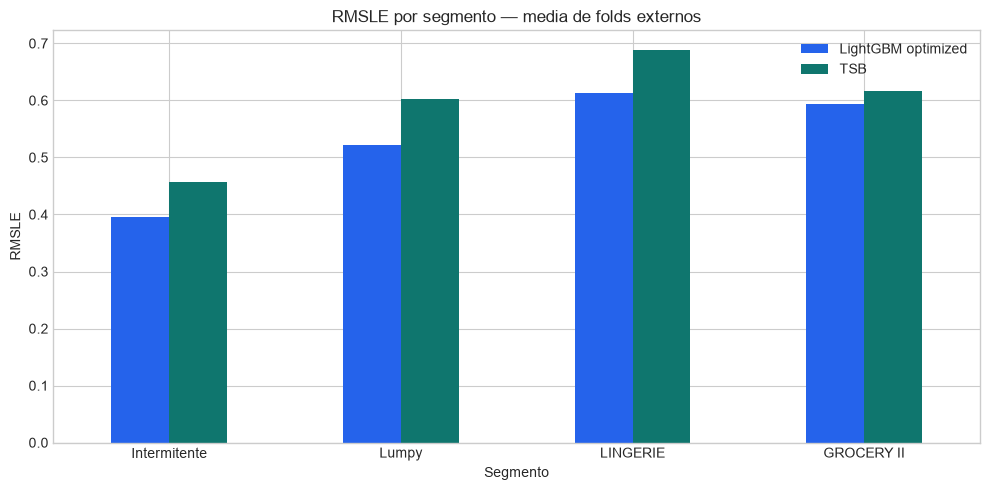

In [8]:
segments = pd.read_csv(V2 / "segment_diagnostics.csv")
focus = segments.loc[
    ((segments["dimension"] == "family") & segments["segment"].isin(["LINGERIE", "GROCERY II"]))
    | ((segments["dimension"] == "demand_type") & segments["segment"].isin(["Intermitente", "Lumpy"]))
]
focus_mean = focus.groupby(["segment", "model"], as_index=False)[["RMSLE", "WAPE_pct"]].mean()
display(focus_mean.round(4))

models_to_compare = ["LightGBM optimized", "TSB"]
plot_data = focus_mean.loc[focus_mean["model"].isin(models_to_compare)].pivot(
    index="segment", columns="model", values="RMSLE"
)
plot_data = plot_data.loc[["Intermitente", "Lumpy", "LINGERIE", "GROCERY II"]]
ax = plot_data.plot(kind="bar", figsize=(10, 5),
                    color=[MODEL_COLORS[name] for name in plot_data.columns])
ax.set(title="RMSLE por segmento — media de folds externos",
       xlabel="Segmento", ylabel="RMSLE")
ax.set_xticklabels(plot_data.index, rotation=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FINAL / "tsb_segment_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

TSB quedó por detrás en `Intermitente`, `Lumpy` y `LINGERIE`. En `GROCERY II` tuvo una ventaja mínima sólo en fold 6 (`0,603039` vs. `0,604174`) y perdió en fold 5. Es una mejora puntual, insuficiente para adoptar un modelo especializado. LightGBM debe seguir como candidato general; un modelo especializado requiere más ventanas y estabilidad por segmento.

## 6. Tres decisiones comerciales

| Decisión | Información necesaria | Resultado BEKANTOR | Acción posible | Limitación principal | Datos reales faltantes |
|---|---|---|---|---|---|
| Compras y reposición | forecast, stock, tránsito, lead time, seguridad y costos | cantidad sugerida y trayectoria simulada | revisar/emitir orden y priorizar riesgo | lead time y costos son supuestos | inventario, recepciones, órdenes, backorders, merma |
| Planificación de promociones | calendario versionado y aprobado | forecast según disponibilidad completa/parcial/nula | anticipar abastecimiento y alertar cambios tardíos | análisis predictivo, no causal | fecha de aprobación, precio, descuento y ejecución |
| Priorización de familias | error, sesgo, ADI/CV², volumen y faltantes | ranking de segmentos difíciles | revisión humana y pilotos focalizados | promedio puede ocultar heterogeneidad | margen, criticidad, shelf life y sustitución |

## Takeaways y conclusión

1. **Forecasting:** LightGBM optimizado obtuvo el menor RMSLE y WAPE medios observados.
2. **Validación:** V2 mejora la separación temporal; dos folds externos no prueban superioridad general ni equivalen a un test ciego final.
3. **Aplicación:** el pronóstico puede orientar reposición, coordinación promocional y priorización de excepciones bajo supuestos explícitos.
4. **Limitaciones:** faltan inventario real, demanda perdida, aprobaciones promocionales, plazos efectivos y costos reales; no hay inferencia causal ni ahorro medido.
5. **Futuro:** validar con datos operativos, ampliar orígenes temporales y estudiar modelos especializados sólo donde la mejora sea estable y accionable.

BEKANTOR pasó de EDA a un sistema experimental reproducible de predicción y simulación. Su valor académico está en la trazabilidad entre información disponible, pronóstico, decisión y limitación; no en presentarlo como un ERP comercial terminado.